# Workshop 3: อ่านตัวอักษร (OCR)
ตัวอย่างงานจริง: อ่านวันหมดอายุ เลข LOT รหัสสินค้า
ขั้นตอน: **ภาพเทา → Threshold แบบ Otsu → Tesseract อ่านข้อความ**

In [3]:
import sys, os
sys.path.insert(0, os.path.abspath("../scripts"))   # ให้หาไฟล์ vision_camera.py เจอ

import cv2
import numpy as np
from vision_camera import show, grab_one, img_path, put_label
print("OpenCV", cv2.__version__, "พร้อมใช้งาน")

OpenCV 4.11.0 พร้อมใช้งาน


In [1]:
import pytesseract, shutil

# Windows: ถ้าหา tesseract ไม่เจอ ให้ชี้ไปที่ตำแหน่งติดตั้งมาตรฐาน
WIN_PATH = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
if shutil.which("tesseract") is None and os.path.exists(WIN_PATH):
    pytesseract.pytesseract.tesseract_cmd = WIN_PATH
print("Tesseract", pytesseract.get_tesseract_version())

Tesseract 5.5.2


## 1. เตรียมภาพ

Otsu เลือกค่า T ให้เอง = 0.0


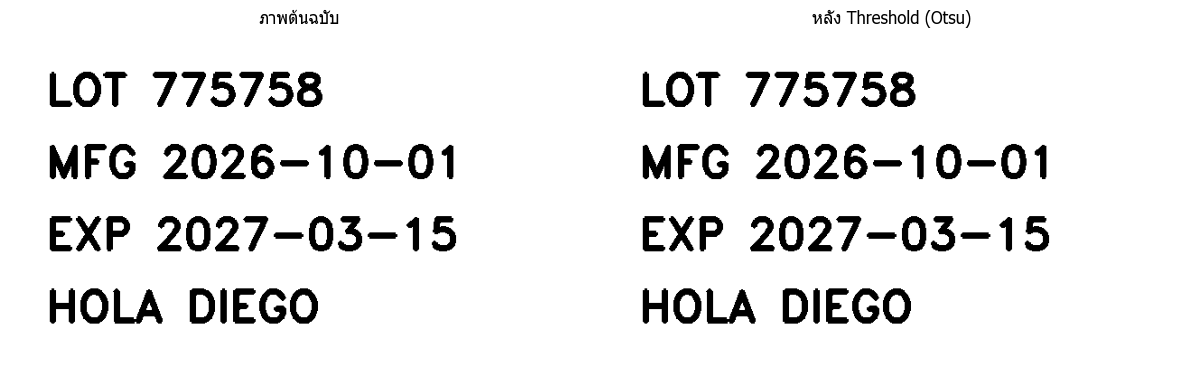

In [6]:
img = cv2.imread(img_path("ocr_sample.png"))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
T, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu เลือกค่า T ให้เอง =", T)
show(img, bw, titles=["ภาพต้นฉบับ", "หลัง Threshold (Otsu)"])

## 2. อ่านข้อความ

LOT 775758
MFG 2026-10-01
EXP 2027-03-15
HOLA DIEGO
ใช้เวลา 130 ms


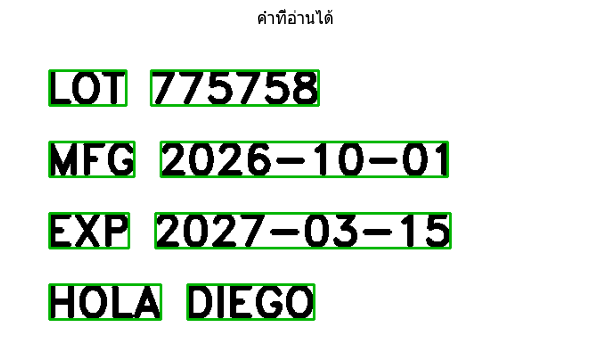

In [7]:
import time

def read_text(img_bw, digits_only=False):
    config = "--psm 6"                       # มองเป็นบล็อกข้อความหลายบรรทัด
    min_conf = 40
    if digits_only:
        config += " -c tessedit_char_whitelist=0123456789-/."
        min_conf = 0                         # โหมดนี้ Tesseract มักรายงานความมั่นใจเป็น 0
    data = pytesseract.image_to_data(img_bw, config=config,
                                     output_type=pytesseract.Output.DICT)
    lines, boxes = {}, []
    for i, word in enumerate(data["text"]):
        if word.strip() and float(data["conf"][i]) >= min_conf:
            key = (data["block_num"][i], data["line_num"][i])
            lines.setdefault(key, []).append(word.strip())
            boxes.append((data["left"][i], data["top"][i], data["width"][i], data["height"][i]))
    return [" ".join(w) for _, w in sorted(lines.items())], boxes

t0 = time.perf_counter()
lines, boxes = read_text(bw)
ms = (time.perf_counter() - t0) * 1000

out = img.copy()
for x, y, w, h in boxes:
    cv2.rectangle(out, (x, y), (x + w, y + h), (0, 180, 0), 2)
for t in lines:
    print(t)
print(f"ใช้เวลา {ms:.0f} ms")
show(out, titles=["คำที่อ่านได้"])

## 3. อ่านเฉพาะตัวเลข

In [8]:
lines, _ = read_text(bw, digits_only=True)
print(lines)

['775758', '2026-10-01', '2027-03-15']


## ลองเอง (ระดับ 2): วันหมดอายุเลยหรือยัง
หาบรรทัดที่ขึ้นต้นด้วย `EXP` แล้วเทียบกับวันนี้ ถ้าเลยแล้ว = **NG**

In [9]:
from datetime import date
import re

lines, _ = read_text(bw)
for t in lines:
    m = re.search(r"EXP\s*(\d{4})-(\d{2})-(\d{2})", t)
    if m:
        exp = date(int(m.group(1)), int(m.group(2)), int(m.group(3)))
        print("วันหมดอายุ:", exp, " ->", "OK" if exp >= date.today() else "NG (หมดอายุแล้ว)")

วันหมดอายุ: 2027-03-15  -> OK


## ถ่ายจากกล้อง
เปลี่ยน `"file"` เป็น `"emu"` หรือ `"basler"` (Restart Kernel ก่อนสลับระหว่าง emu กับ basler)

In [15]:
frame = grab_one("file", image="ocr_sample.png", exposure_us=20000)
g = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
_, b = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(read_text(b)[0])

เชื่อมต่อกล้อง: acA2440-20gc
  ตั้ง GevSCPD = 1000
  ตั้ง ExposureAuto = Off
  ตั้ง ExposureTimeAbs = 20000
  ตั้ง GainAuto = Off
  ตั้ง GainRaw = 0
['{']


---
# ลงมือทำ: จากอ่านได้ สู่ตรวจฉลากได้จริง (5 ภารกิจ)
อ่านตัวอักษรได้ยังไม่พอ  สถานีตรวจฉลากต้อง**ดึงข้อมูล ตรวจกฎ และตัดสิน**  เฉลยอยู่ท้าย notebook

In [ ]:
def check(title, got, expected):
    ok = got == expected
    print(('✅ ผ่าน  ' if ok else '❌ ยัง   ') + title + f'   ได้ {got}  ต้องการ {expected}')
    return ok

import re
from datetime import date
TEXT = 'PRODUCT A LOT 775758 MFG 2026-10-01 EXP 2027-03-15'
TODAY = date(2026, 10, 11)                         # วันที่อ้างอิงของแบบฝึก
print('พร้อม')

## ภารกิจ 1: ดึงเลข LOT
ใช้ `re.search` หาคำว่า LOT ตามด้วยตัวเลข 6 หลัก แล้วคืนเฉพาะตัวเลข  ถ้าไม่มีให้คืน `None`
คำใบ้: รูปแบบ `r'LOT§s*(§d{6})'`  แล้วใช้ `.group(1)`

In [ ]:
def get_lot(text):
    return None                                    # TODO

check('ภารกิจ 1 LOT', get_lot(TEXT), '775758')
check('ภารกิจ 1 ไม่มี LOT', get_lot('PRODUCT A EXP 2027-03-15'), None)

## ภารกิจ 2: เหลืออายุกี่วัน
หา `EXP ปปปป-ดด-วว` แปลงเป็น `date` แล้วลบด้วย `TODAY`  ไม่ตัวพิมพ์เล็ก/ใหญ่ (`re.IGNORECASE`)  ถ้าไม่มี EXP ให้คืน `None`

In [ ]:
def days_left(text):
    return 0                                       # TODO

check('ภารกิจ 2 วันที่เหลือ', days_left(TEXT), 155)
check('ภารกิจ 2 ตัวพิมพ์เล็ก', days_left('lot 775758 exp 2026-10-21'), 10)
check('ภารกิจ 2 ไม่มี EXP', days_left('LOT 775758'), None)

## ภารกิจ 3: กฎตัดสินฉลาก
NG เมื่อ: ไม่มี LOT (`NO_LOT`)  ไม่มี EXP (`NO_EXP`)  เหลืออายุน้อยกว่า 30 วัน (`SHORT_LIFE`)  ส่งรายการสาเหตุทั้งหมดกลับไป

In [ ]:
def judge_label(text):
    reasons = []
    if get_lot(text) is None:
        reasons.append('NO_LOT')
    # TODO: เพิ่ม NO_EXP และ SHORT_LIFE
    return ('OK' if not reasons else 'NG'), reasons

check('ภารกิจ 3 ฉลากดี', judge_label(TEXT), ('OK', []))
check('ภารกิจ 3 ไม่มี EXP', judge_label('PRODUCT A LOT 775758'), ('NG', ['NO_EXP']))
check('ภารกิจ 3 ใกล้หมดอายุ', judge_label('LOT 775758 EXP 2026-10-20'), ('NG', ['SHORT_LIFE']))

## ภารกิจ 4: ต่อทั้งระบบกับภาพจริง
ภาพ → ภาพเทา → Threshold (Otsu) → OCR → `judge_label`  ใช้กับฉลากสินค้า 2 ภาพจาก notebook 06

In [ ]:
def inspect_label_image(path):
    img = cv2.imread(path)
    text = ''                                      # TODO: แปลงเป็นภาพเทา, threshold แบบ Otsu, อ่านด้วย pytesseract (config --psm 6)
    return judge_label(text)[0]

check('ภารกิจ 4 ฉลากดี', inspect_label_image(img_path('industrial/label_01_good.png')), 'OK')
check('ภารกิจ 4 ฉลากไม่มี EXP', inspect_label_image(img_path('industrial/label_02_no_exp.png')), 'NG')

## ภารกิจ 5 (ท้าทาย): ฉลากเอียง อ่านวันที่ผิด
ฉลากเอียง 6° ทำให้ OCR อ่าน **15** เป็น **19** ได้  ต้อง**หมุนภาพกลับให้ตรง**ก่อนอ่าน
วิธี: หาพิกเซลตัวอักษรทั้งหมด → `cv2.minAreaRect` ได้มุมเอียง → หมุนกลับด้วย `cv2.warpAffine`

In [ ]:
src = cv2.imread(img_path('ocr_sample.png'))
h, w = src.shape[:2]
tilted = cv2.warpAffine(src, cv2.getRotationMatrix2D((w / 2, h / 2), 6, 1), (w, h), borderValue=(255, 255, 255))

def deskew(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    angle = 0.0                                    # TODO: หามุมจาก cv2.minAreaRect(cv2.findNonZero(bw)) (ค่าที่ 3 ของผลลัพธ์)
    if angle > 45:
        angle -= 90
    M = cv2.getRotationMatrix2D((img.shape[1] / 2, img.shape[0] / 2), angle, 1)
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), borderValue=(255, 255, 255))

fixed = deskew(tilted)
g = cv2.cvtColor(fixed, cv2.COLOR_BGR2GRAY)
_, b = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
text = pytesseract.image_to_string(b, config='--psm 6')
show(tilted, fixed, titles=['ฉลากเอียง', 'หลังหมุนกลับ'], size=4)
check('ภารกิจ 5 อ่านวันหมดอายุถูก', days_left(text), 155)

<details>
<summary><b>เฉลย (คลิกเพื่อเปิด)</b></summary>

**ภารกิจ 1:**
```python
m = re.search(r'LOT§s*(§d{6})', text, re.IGNORECASE)
return m.group(1) if m else None
```

**ภารกิจ 2:**
```python
m = re.search(r'EXP§s*(§d{4})-(§d{2})-(§d{2})', text, re.IGNORECASE)
if not m:
    return None
return (date(int(m.group(1)), int(m.group(2)), int(m.group(3))) - TODAY).days
```

**ภารกิจ 3:**
```python
d = days_left(text)
if d is None:
    reasons.append('NO_EXP')
elif d < 30:
    reasons.append('SHORT_LIFE')
```

**ภารกิจ 4:**
```python
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
text = pytesseract.image_to_string(bw, config='--psm 6')
```

**ภารกิจ 5:** `angle = cv2.minAreaRect(cv2.findNonZero(bw))[2]`
</details>